In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

sns.set_theme(style="whitegrid", palette="deep")

In [3]:
from pathlib import Path

PROJECT_ROOT = Path(
    r"C:\Users\Dell_User\Documents\BI_Projects\inventory-demand-analysis"
)

DATA_DIR = PROJECT_ROOT / "data" / "processed"
IMAGES_DIR = PROJECT_ROOT / "images"

SALES_FILE = DATA_DIR / "sales_clean.csv"
INVENTORY_FILE = DATA_DIR / "inventory_clean.csv"
METRICS_FILE = DATA_DIR / "product_store_metrics.csv"

print("Project root:", PROJECT_ROOT)
print("Data directory:", DATA_DIR)
print("Sales file exists:", SALES_FILE.exists())
print("Inventory file exists:", INVENTORY_FILE.exists())
print("Metrics file exists:", METRICS_FILE.exists())

Project root: C:\Users\Dell_User\Documents\BI_Projects\inventory-demand-analysis
Data directory: C:\Users\Dell_User\Documents\BI_Projects\inventory-demand-analysis\data\processed
Sales file exists: True
Inventory file exists: True
Metrics file exists: True


In [4]:
sales = pd.read_csv(
    SALES_FILE,
    parse_dates=[
        "transaction_date",
        "sales_month_start",
        "sales_week_start"
    ],
    low_memory=False
)

inventory = pd.read_csv(
    INVENTORY_FILE,
    parse_dates=[
        "start_date",
        "end_date",
        "inventory_month_start",
        "inventory_week_start"
    ],
    low_memory=False
)

metrics = pd.read_csv(
    METRICS_FILE,
    parse_dates=["inventory_date"],
    low_memory=False
)

In [5]:
print(f"Sales: {sales.shape[0]:,} rows × {sales.shape[1]} columns")
print(
    f"Inventory: {inventory.shape[0]:,} rows × "
    f"{inventory.shape[1]} columns"
)
print(
    f"Product-store metrics: {metrics.shape[0]:,} rows × "
    f"{metrics.shape[1]} columns"
)

Sales: 125,751 rows × 31 columns
Inventory: 284,755 rows × 33 columns
Product-store metrics: 60,968 rows × 27 columns


In [6]:
display(sales.head())
display(inventory.head())
display(metrics.head())

,sales_row_id,transaction_date,sales_type,is_return,transaction_type,return_reason,supplier,product_no,product_description,product_division,product_category,product_subcategory,product_segment,store_id,sales_channel,quantity_sold,sales_amount,cogs,gross_profit,transaction_count,product_store_key,sales_year,sales_quarter,sales_month_number,sales_month,sales_week,sales_day,sales_month_start,sales_week_start,sales_year_month,sales_year_month_sort
0,1,2025-09-01,Full Price,0,Sale,NaN,Vendor 0169,PROD-139867,PROD-100449 SEG-500065 Scholar Footwear Trailb...,Scholar Footwear,Scholar Footwear Trailblazer,Scholar Footwear Trailblazer Equilibrium,SEG-500065 Scholar Footwear Trailblazer Equili...,STR-1006,Channel Alpha,1,115.00,52.31,62.69,1,PROD-139867|STR-1006,2025,3,9,September,36,Monday,2025-09-01,2025-08-31,2025-09,202509
1,2,2025-09-07,Full Price,0,Sale,NaN,Vendor 0166,PROD-100449,PROD-100825 SEG-500112 Heritage Footwear Fligh...,Femme Footwear,Femme Footwear Flight Classic,Femme Footwear Flight Classic Varied,SEG-500112 Heritage Footwear Flight Classic Ze...,STR-1198,Channel Alpha,1,115.00,58.47,56.53,1,PROD-100449|STR-1198,2025,3,9,September,37,Sunday,2025-09-01,2025-09-07,2025-09,202509
2,3,2025-08-06,Promo,0,Sale,NaN,Vendor 0169,PROD-153623,PROD-148813 SEG-511388 Scholar Footwear Trailb...,Scholar Footwear,Scholar Footwear Trailblazer,Scholar Footwear Trailblazer Equilibrium,SEG-511388 Scholar Footwear Trailblazer Equili...,STR-1157,Channel Alpha,1,79.99,43.76,36.23,1,PROD-153623|STR-1157,2025,3,8,August,32,Wednesday,2025-08-01,2025-08-03,2025-08,202508
3,4,2025-08-31,Full Price,0,Sale,NaN,Vendor 0246,PROD-140876,PROD-100419 SEG-500063 Scholar Footwear Boot C...,Scholar Footwear,Scholar Footwear Boot Collection,Scholar Footwear Boot Collection Woodland,SEG-500063 Scholar Footwear Boot Collection Wo...,STR-1234,Channel Alpha,1,110.00,50.60,59.40,1,PROD-140876|STR-1234,2025,3,8,August,36,Sunday,2025-08-01,2025-08-31,2025-08,202508
4,5,2026-03-22,Full Price,0,Sale,NaN,Vendor 0169,PROD-166113,PROD-149345 SEG-511444 Femme Footwear Trailbla...,Femme Footwear,Femme Footwear Trailblazer,Femme Footwear Trailblazer Equilibrium,SEG-511444 Femme Footwear Trailblazer Equilibrium,STR-1157,Channel Alpha,1,160.00,77.95,82.05,1,PROD-166113|STR-1157,2026,1,3,March,13,Sunday,2026-03-01,2026-03-22,2026-03,202603


,inventory_row_id,start_date,end_date,inventory_year,inventory_quarter,inventory_month_number,inventory_month,inventory_week,inventory_day,inventory_month_start,inventory_week_start,inventory_year_month,inventory_year_month_sort,inventory_period_days,stock_status,availability_status,stockout_days,supplier,product_no,product_description,product_division,product_category,product_subcategory,product_segment,store_id,store_type,sales_channel,quantity_on_hand,stock_selling_value,stock_cost_value,unit_selling_price,unit_cost_price,product_store_key
0,1,2025-08-07,2025-10-18,2025,3,8,August,32,Thursday,2025-08-01,2025-08-04,2025-08,202508,73,Full Price,In Stock,0,Vendor 0255,PROD-159369,PROD-103395 SEG-500461 Scholar Footwear Canvas...,Scholar Footwear,Scholar Footwear Canvas Styles,Scholar Footwear Canvas Styles Drifter,SEG-500461 Scholar Footwear Canvas Styles Drifter,STR-1010,Retail Storefront,Channel Alpha,1,55.00,24.75,55.00,24.75,PROD-159369|STR-1010
1,2,2026-02-15,2026-02-15,2026,1,2,February,7,Sunday,2026-02-01,2026-02-09,2026-02,202602,1,Full Price,In Stock,0,Vendor 0010,PROD-180713,PROD-190644 SEG-520887 Femme Footwear Court Ca...,Femme Footwear,Femme Footwear Court Casual,Femme Footwear Court Casual Trident,SEG-520887 Femme Footwear Court Casual Trident,STR-1082,Retail Storefront,Channel Alpha,1,130.00,59.73,130.00,59.73,PROD-180713|STR-1082
2,3,2026-01-08,2026-02-15,2026,1,1,January,2,Thursday,2026-01-01,2026-01-05,2026-01,202601,39,Full Price,In Stock,0,Vendor 0166,PROD-169474,PROD-153439 SEG-512518 Femme Footwear Court Ca...,Femme Footwear,Femme Footwear Court Casual,Femme Footwear Court Casual Zephyr,SEG-512518 Femme Footwear Court Casual Zephyr,STR-1105,Retail Storefront,Channel Alpha,1,120.00,60.44,120.00,60.44,PROD-169474|STR-1105
3,4,2025-12-23,2026-02-15,2025,4,12,December,52,Tuesday,2025-12-01,2025-12-22,2025-12,202512,55,Full Price,In Stock,0,Vendor 0106,PROD-170976,PROD-122029 SEG-504463 Junior Apparel Cozy Pul...,Junior Apparel,Junior Apparel Cozy Pullovers,Junior Apparel Cozy Pullovers Varied,SEG-504463 Junior Apparel Cozy Pullovers Varied,STR-1157,Retail Storefront,Channel Alpha,3,150.00,52.50,50.00,17.50,PROD-170976|STR-1157
4,5,2026-02-10,9999-12-31,2026,1,2,February,7,Tuesday,2026-02-01,2026-02-09,2026-02,202602,2912403,Full Price,In Stock,0,Vendor 0134,PROD-183525,PROD-111954 SEG-502325 Scholar Footwear Modern...,Scholar Footwear,Scholar Footwear Modern Legend,Scholar Footwear Modern Legend Summit,SEG-502325 Scholar Footwear Modern Legend Summit,STR-1253,Retail Storefront,Channel Alpha,4,360.00,182.16,90.00,45.54,PROD-183525|STR-1253


,product_store_key,product_no,product_description,product_division,product_category,product_subcategory,product_segment,supplier,store_id,store_type,sales_channel,inventory_date,stock_status,availability_status,quantity_on_hand,stock_cost_value,stock_selling_value,unit_cost_price,unit_selling_price,gross_units_sold,returned_units,net_units_sold,net_sales,gross_profit,average_daily_demand,estimated_days_of_supply,replenishment_status
0,PROD-100043|STR-1006,PROD-100043,PROD-189472 SEG-520541 Femme Footwear Boot Col...,Femme Footwear,Femme Footwear Boot Collection,Femme Footwear Boot Collection Plushfoot,SEG-520541 Femme Footwear Boot Collection Plus...,Vendor 0064,STR-1006,Retail Storefront,Channel Alpha,9999-12-31,Full Price,In Stock,1,67.61,160.00,67.61,160.00,1,0,1,96.00,27.26,0.00,328.00,Possible Excess Stock
1,PROD-100043|STR-1010,PROD-100043,PROD-189472 SEG-520541 Femme Footwear Boot Col...,Femme Footwear,Femme Footwear Boot Collection,Femme Footwear Boot Collection Plushfoot,SEG-520541 Femme Footwear Boot Collection Plus...,Vendor 0064,STR-1010,Retail Storefront,Channel Alpha,9999-12-31,Full Price,In Stock,2,136.03,320.00,68.02,160.00,1,0,1,160.00,91.98,0.00,656.00,Possible Excess Stock
2,PROD-100043|STR-1026,PROD-100043,PROD-189472 SEG-520541 Femme Footwear Boot Col...,Femme Footwear,Femme Footwear Boot Collection,Femme Footwear Boot Collection Plushfoot,SEG-520541 Femme Footwear Boot Collection Plus...,Vendor 0064,STR-1026,Retail Storefront,Channel Alpha,9999-12-31,Full Price,In Stock,1,69.01,160.00,69.01,160.00,1,1,0,0.00,0.00,0.00,NaN,Non-Moving Stock
3,PROD-100043|STR-1044,PROD-100043,PROD-189472 SEG-520541 Femme Footwear Boot Col...,Femme Footwear,Femme Footwear Boot Collection,Femme Footwear Boot Collection Plushfoot,SEG-520541 Femme Footwear Boot Collection Plus...,Vendor 0064,STR-1044,Retail Storefront,Channel Alpha,9999-12-31,Full Price,In Stock,1,69.14,160.00,69.14,160.00,0,0,0,0.00,0.00,0.00,NaN,Non-Moving Stock
4,PROD-100043|STR-1074,PROD-100043,PROD-189472 SEG-520541 Femme Footwear Boot Col...,Femme Footwear,Femme Footwear Boot Collection,Femme Footwear Boot Collection Plushfoot,SEG-520541 Femme Footwear Boot Collection Plus...,Vendor 0064,STR-1074,Retail Storefront,Channel Alpha,9999-12-31,Full Price,In Stock,1,67.99,160.00,67.99,160.00,1,1,0,0.00,-0.01,0.00,NaN,Non-Moving Stock


In [7]:
sales.info()

<class 'pandas.DataFrame'>
RangeIndex: 125751 entries, 0 to 125750
Data columns (total 31 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   sales_row_id           125751 non-null  int64         
 1   transaction_date       125751 non-null  datetime64[us]
 2   sales_type             125751 non-null  str           
 3   is_return              125751 non-null  int64         
 4   transaction_type       125751 non-null  str           
 5   return_reason          0 non-null       float64       
 6   supplier               125751 non-null  str           
 7   product_no             125751 non-null  str           
 8   product_description    125751 non-null  str           
 9   product_division       125751 non-null  str           
 10  product_category       125751 non-null  str           
 11  product_subcategory    125751 non-null  str           
 12  product_segment        125751 non-null  str           


In [8]:
inventory.info()

<class 'pandas.DataFrame'>
RangeIndex: 284755 entries, 0 to 284754
Data columns (total 33 columns):
 #   Column                     Non-Null Count   Dtype         
---  ------                     --------------   -----         
 0   inventory_row_id           284755 non-null  int64         
 1   start_date                 284755 non-null  datetime64[us]
 2   end_date                   284755 non-null  datetime64[us]
 3   inventory_year             284755 non-null  int64         
 4   inventory_quarter          284755 non-null  int64         
 5   inventory_month_number     284755 non-null  int64         
 6   inventory_month            284755 non-null  str           
 7   inventory_week             284755 non-null  int64         
 8   inventory_day              284755 non-null  str           
 9   inventory_month_start      284755 non-null  datetime64[us]
 10  inventory_week_start       284755 non-null  datetime64[us]
 11  inventory_year_month       284755 non-null  str           
 12 

In [9]:
metrics.info()

<class 'pandas.DataFrame'>
RangeIndex: 60968 entries, 0 to 60967
Data columns (total 27 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   product_store_key         60968 non-null  str           
 1   product_no                60968 non-null  str           
 2   product_description       60968 non-null  str           
 3   product_division          60968 non-null  str           
 4   product_category          60968 non-null  str           
 5   product_subcategory       60968 non-null  str           
 6   product_segment           60968 non-null  str           
 7   supplier                  60968 non-null  str           
 8   store_id                  60968 non-null  str           
 9   store_type                60968 non-null  str           
 10  sales_channel             60968 non-null  str           
 11  inventory_date            60968 non-null  datetime64[us]
 12  stock_status              609

**Check for missing values**

In [10]:
#Check for missing values in the datasets
print("Missing values in Sales:")
print(sales.isnull().sum())


Missing values in Sales:
sales_row_id                  0
transaction_date              0
sales_type                    0
is_return                     0
transaction_type              0
return_reason            125751
supplier                      0
product_no                    0
product_description           0
product_division              0
product_category              0
product_subcategory           0
product_segment               0
store_id                      0
sales_channel                 0
quantity_sold                 0
sales_amount                  0
cogs                          0
gross_profit                  0
transaction_count             0
product_store_key             0
sales_year                    0
sales_quarter                 0
sales_month_number            0
sales_month                   0
sales_week                    0
sales_day                     0
sales_month_start             0
sales_week_start              0
sales_year_month              0
sales_year_mont

In [11]:
print("\nMissing values in Inventory:")
print(inventory.isnull().sum())


Missing values in Inventory:
inventory_row_id             0
start_date                   0
end_date                     0
inventory_year               0
inventory_quarter            0
inventory_month_number       0
inventory_month              0
inventory_week               0
inventory_day                0
inventory_month_start        0
inventory_week_start         0
inventory_year_month         0
inventory_year_month_sort    0
inventory_period_days        0
stock_status                 0
availability_status          0
stockout_days                0
supplier                     0
product_no                   0
product_description          0
product_division             0
product_category             0
product_subcategory          0
product_segment              0
store_id                     0
store_type                   0
sales_channel                0
quantity_on_hand             0
stock_selling_value          0
stock_cost_value             0
unit_selling_price           0
unit_cost

In [12]:
print("\nMissing values in Product-store metrics:")
print(metrics.isnull().sum())


Missing values in Product-store metrics:
product_store_key               0
product_no                      0
product_description             0
product_division                0
product_category                0
product_subcategory             0
product_segment                 0
supplier                        0
store_id                        0
store_type                      0
sales_channel                   0
inventory_date                  0
stock_status                    0
availability_status             0
quantity_on_hand                0
stock_cost_value                0
stock_selling_value             0
unit_cost_price                 0
unit_selling_price              0
gross_units_sold                0
returned_units                  0
net_units_sold                  0
net_sales                       0
gross_profit                    0
average_daily_demand            0
estimated_days_of_supply    14094
replenishment_status            0
dtype: int64


**Check for duplicates**

In [13]:
print(
    "Duplicate sales IDs:",
    sales["sales_row_id"].duplicated().sum()
)

print(
    "Duplicate inventory IDs:",
    inventory["inventory_row_id"].duplicated().sum()
)

print(
    "Duplicate product-store keys in metrics:",
    metrics["product_store_key"].duplicated().sum()
)

Duplicate sales IDs: 0
Duplicate inventory IDs: 0
Duplicate product-store keys in metrics: 0


**EDA Summary**

In [14]:
eda_summary = pd.DataFrame({
    "metric": [
        "Sales records",
        "Inventory records",
        "Product-store metric records",
        "Sales start date",
        "Sales end date",
        "Distinct products sold",
        "Distinct sales stores",
        "Net units sold",
        "Net sales",
        "Net gross profit",
        "Latest units on hand",
        "Latest stock cost value"
    ],
    "value": [
        f"{len(sales):,}",
        f"{len(inventory):,}",
        f"{len(metrics):,}",
        sales["transaction_date"].min().date(),
        sales["transaction_date"].max().date(),
        f"{sales['product_no'].nunique():,}",
        f"{sales['store_id'].nunique():,}",
        f"{sales['quantity_sold'].sum():,.0f}",
        f"{sales['sales_amount'].sum():,.2f}",
        f"{sales['gross_profit'].sum():,.2f}",
        f"{metrics['quantity_on_hand'].sum():,.0f}",
        f"{metrics['stock_cost_value'].sum():,.2f}"
    ]
})

display(eda_summary)

,metric,value
0,Sales records,"125,751"
1,Inventory records,"284,755"
2,Product-store metric records,"60,968"
3,Sales start date,2025-06-01
4,Sales end date,2026-04-24
5,Distinct products sold,"2,326"
6,Distinct sales stores,40
7,Net units sold,"116,995"
8,Net sales,"10,482,110.25"
9,Net gross profit,"4,634,359.16"


In [15]:
eda_summary.to_csv(
    DATA_DIR / "eda_summary.csv",
    index=False
)

**Plot monthly demand**

In [16]:
monthly_demand = (
    sales.groupby(
        ["sales_month_start", "sales_year_month"],
        as_index=False
    )
    .agg(
        net_units_sold=("quantity_sold", "sum"),
        net_sales=("sales_amount", "sum"),
        gross_profit=("gross_profit", "sum")
    )
    .sort_values("sales_month_start")
)

display(monthly_demand.head())

,sales_month_start,sales_year_month,net_units_sold,net_sales,gross_profit
0,2025-06-01,2025-06,7712,"706,683.44","332,964.51"
1,2025-07-01,2025-07,9545,"855,571.55","392,780.10"
2,2025-08-01,2025-08,17561,"1,535,117.21","703,591.11"
3,2025-09-01,2025-09,9654,"860,457.23","372,588.28"
4,2025-10-01,2025-10,9226,"821,266.08","351,700.49"


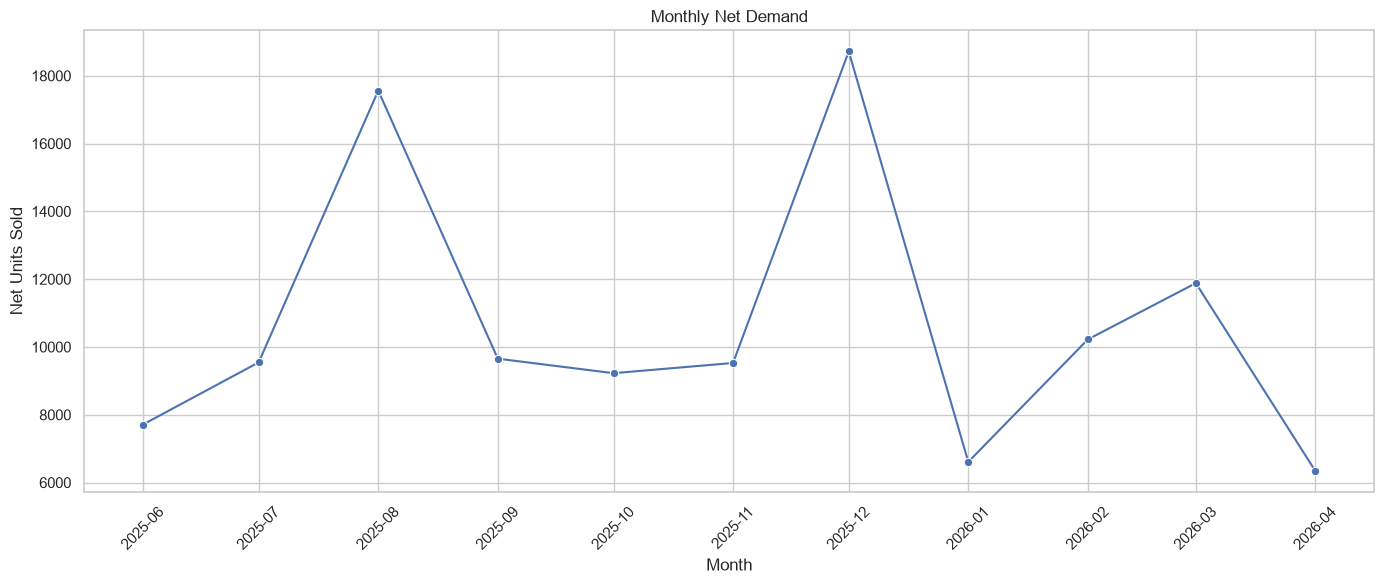

In [17]:
fig, ax = plt.subplots(figsize=(14, 6))

sns.lineplot(
    data=monthly_demand,
    x="sales_month_start",
    y="net_units_sold",
    marker="o",
    ax=ax
)

ax.set_title("Monthly Net Demand")
ax.set_xlabel("Month")
ax.set_ylabel("Net Units Sold")

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    IMAGES_DIR / "monthly_net_demand.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Plot replenishment classifications**

In [18]:
status_summary = (
    metrics.groupby("replenishment_status", as_index=False)
    .agg(
        product_store_records=("product_store_key", "count"),
        units_on_hand=("quantity_on_hand", "sum"),
        stock_cost_value=("stock_cost_value", "sum")
    )
    .sort_values(
        "product_store_records",
        ascending=False
    )
)

display(status_summary)

,replenishment_status,product_store_records,units_on_hand,stock_cost_value
2,Possible Excess Stock,34330,49510,"2,423,112.39"
1,Non-Moving Stock,13290,22265,"1,120,453.13"
4,Urgent Replenishment,8085,-697,"-28,519.95"
0,Adequate Stock,5252,4538,"229,496.00"
3,Replenish Soon,11,12,534.47


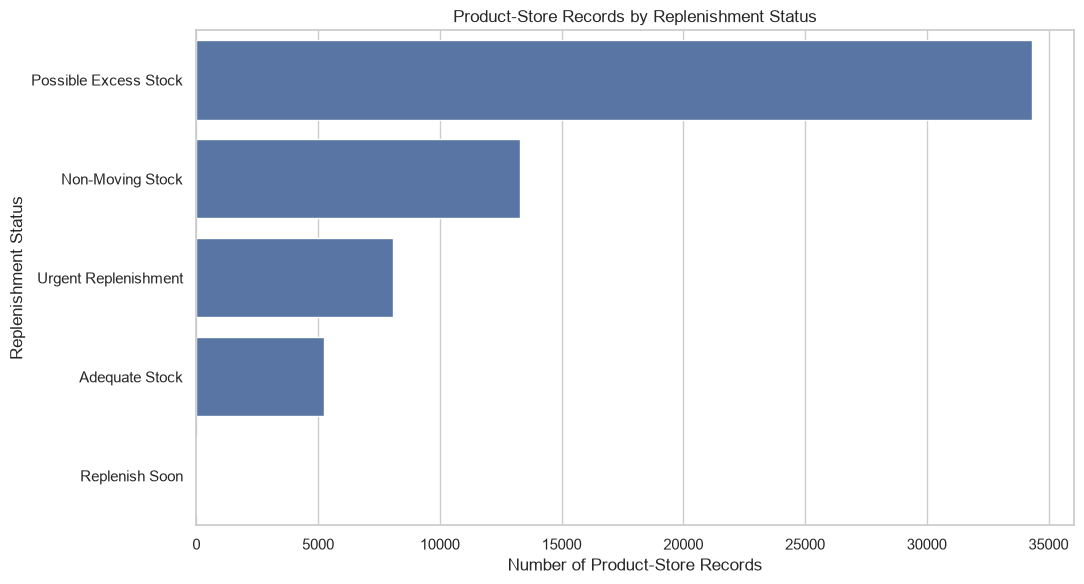

In [19]:
fig, ax = plt.subplots(figsize=(11, 6))

sns.barplot(
    data=status_summary,
    x="product_store_records",
    y="replenishment_status",
    ax=ax
)

ax.set_title("Product-Store Records by Replenishment Status")
ax.set_xlabel("Number of Product-Store Records")
ax.set_ylabel("Replenishment Status")

plt.tight_layout()

plt.savefig(
    IMAGES_DIR / "replenishment_status_summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()